# LeNet：识别手写数字

目标：把 28×28 的灰度图像变成十个类别的得分。卷积提取局部图案，池化缩小特征图，Flatten 将特征图展平后交给 Linear 分类。

从项目根目录运行。`device` 可换为 `"cpu"` 或 `"cuda"`；不固定随机种子。首次读取会下载原版 MNIST，之后使用本地缓存。

In [2]:
from qutai import Stream, nn, visualization
from examples.data.data import load_mnist

device = "apple"

## 1. 看数据

图像形状为（批次，通道，高，宽）。MNIST 只有一个灰度通道。为了快速看清流程，先用 256 张图像、每批 32 张；可以修改 `limit` 扩大训练集。

一批图像的形状： (32, 1, 28, 28)



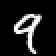
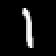
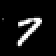
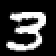

In [4]:
train_inputs, train_targets = load_mnist("train")
test_inputs, test_targets = load_mnist("test")
data = Stream(train_inputs, train_targets, batch_size=32, limit=256,  device=device, progress=False)
inputs, targets = next(iter(data))
print("一批图像的形状：", inputs.shape)
visualization.ImageCombine([visualization.Image.from_tensor(image, value_range=(0, 1), scale=2) for image in inputs[:4]], labels=targets[:4], title="真实 MNIST 与正确标签")

## 2. 搭模型

两组卷积、ReLU、池化之后，图像变成 16×5×5 个特征。展平后的 400 个数经过全连接层，输出 0～9 的得分。

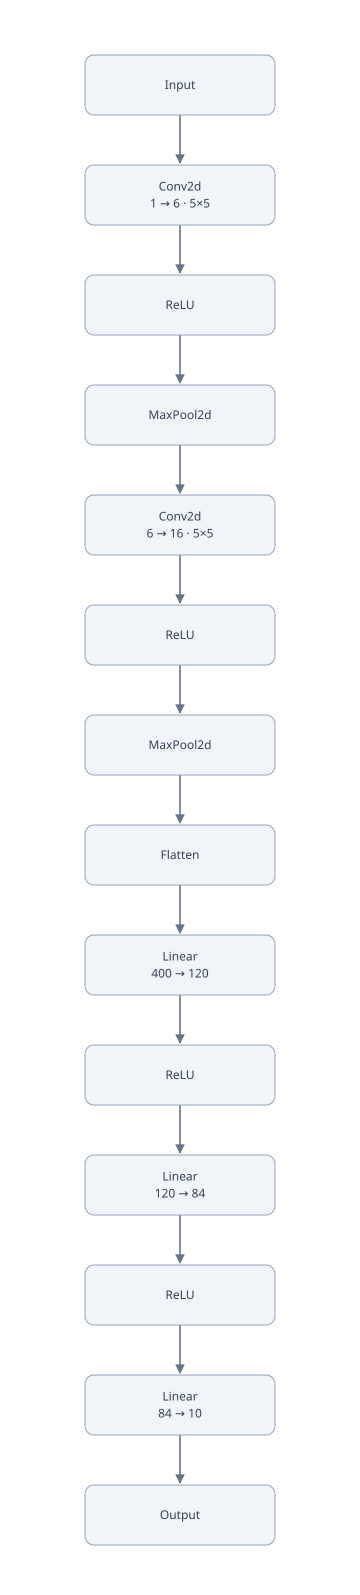

In [5]:
model = nn.Model([
    nn.Conv2d(1, 6, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(6, 16, 5), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(400, 120), nn.ReLU(),
    nn.Linear(120, 84), nn.ReLU(),
    nn.Linear(84, 10),
]).to(device)
optimizer = nn.AdamW(model, learning_rate=0.003)
loss_function = nn.CrossEntropy()

visualization.Network(model)

## 3. 训练

每一轮从 Stream 重新取批次。与 Iris 的区别只在模型和输入形状，交叉熵与更新步骤完全相同。

In [8]:
epochs = 50
# 每轮遍历一次数据；每批独立完成一次参数更新。
for epoch in range(epochs):
    for inputs, targets in data:
        optimizer.zero_grad()
        loss = loss_function(model(inputs), targets)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch + 1}/{epochs}  loss {loss.item():.6f}")

epoch 1/50  loss 0.001093
epoch 2/50  loss 0.002369
epoch 3/50  loss 0.001111
epoch 4/50  loss 0.000992
epoch 5/50  loss 0.000793
epoch 6/50  loss 0.000724
epoch 7/50  loss 0.000372
epoch 8/50  loss 0.000733
epoch 9/50  loss 0.000708
epoch 10/50  loss 0.000336
epoch 11/50  loss 0.000611
epoch 12/50  loss 0.000419
epoch 13/50  loss 0.000531
epoch 14/50  loss 0.000255
epoch 15/50  loss 0.000552
epoch 16/50  loss 0.000187
epoch 17/50  loss 0.000319
epoch 18/50  loss 0.000353
epoch 19/50  loss 0.000477
epoch 20/50  loss 0.000368
epoch 21/50  loss 0.000583
epoch 22/50  loss 0.000346
epoch 23/50  loss 0.000334
epoch 24/50  loss 0.000380
epoch 25/50  loss 0.000231
epoch 26/50  loss 0.000348
epoch 27/50  loss 0.000393
epoch 28/50  loss 0.000351
epoch 29/50  loss 0.000310
epoch 30/50  loss 0.000320
epoch 31/50  loss 0.000067
epoch 32/50  loss 0.000186
epoch 33/50  loss 0.000246
epoch 34/50  loss 0.000341
epoch 35/50  loss 0.000235
epoch 36/50  loss 0.000399
epoch 37/50  loss 0.000193
epoch 38/5

## 4. 看结果

在未参与训练的测试图上取最高分类得分，显示正确数字与预测数字。这里只训练了一个很小的子集，效果会随初始化变化；增大数据量和 epoch 可以继续训练。

这 64 张测试图的准确率：84.4%



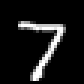
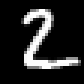
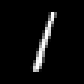
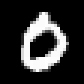

In [9]:
inputs, targets = next(iter(Stream(test_inputs, test_targets, batch_size=64, shuffle=False, device=device, progress=False)))
predictions = model(inputs, train=False).argmax(axis=-1)
correct = sum(prediction == target for prediction, target in zip(predictions, targets))
print(f"这 64 张测试图的准确率：{correct / len(targets):.1%}")
visualization.ImageCombine([visualization.Image.from_tensor(image, value_range=(0, 1), scale=3) for image in inputs[:4]], labels=[f"正确 {target} / 预测 {prediction}" for target, prediction in zip(targets[:4], predictions[:4])])